## Precession and Sequence Plots

In [6]:
# imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# import r2_by_condition.csv file
df = pd.read_csv('/Users/liviastein/STDP_Theta-1/ResultPipelines/r2_by_condition.csv')
df.head()

,condition,cell_id,r_squared,slope,n_spikes,r_value,p_value,std_err
0,0.0,10,0.639952,-1.542290,3039,-0.799970,0.0,0.020992
1,0.0,11,0.661494,-1.563820,3084,-0.813323,0.0,0.020151
2,0.0,12,0.653085,-1.575010,3210,-0.808137,0.0,0.020267
3,0.0,13,0.659327,-1.566716,3016,-0.811989,0.0,0.020513
4,0.0,14,0.657107,-1.560879,3142,-0.810621,0.0,0.020122


In [5]:
df.dtypes

condition    float64
cell_id        int64
r_squared    float64
slope        float64
n_spikes       int64
r_value      float64
p_value      float64
std_err      float64
dtype: object

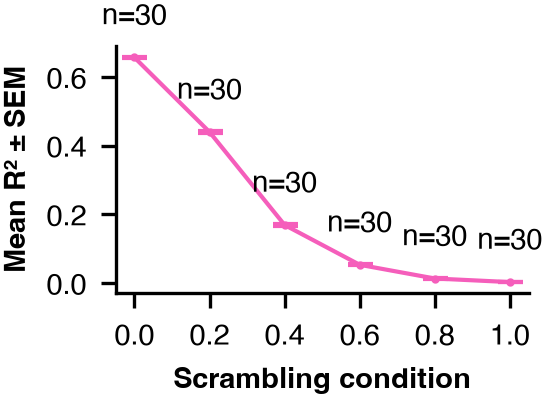

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#df = pd.read_csv("r2_by_condition.csv")
#df = df.dropna(subset=["r_squared"]) 

summary = df.groupby("condition")["r_squared"].agg(["mean", "sem", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(2, 1.5))
ax.errorbar(summary["condition"], summary["mean"], yerr=summary["sem"],
            marker='o', color="#f55ebb", capsize=3, linewidth=1)

for _, row in summary.iterrows():
    ax.annotate(f"n={int(row['count'])}", (row["condition"], row["mean"]),
                textcoords="offset points", xytext=(0, 8), fontsize=7, ha='center')
ax.set_xlabel("Scrambling condition")
ax.set_ylabel("Mean R² ± SEM")
ax.set_xticks(summary["condition"])  # explicitly show ticks only at your actual sampled values
sns.despine()
plt.tight_layout()
plt.show()

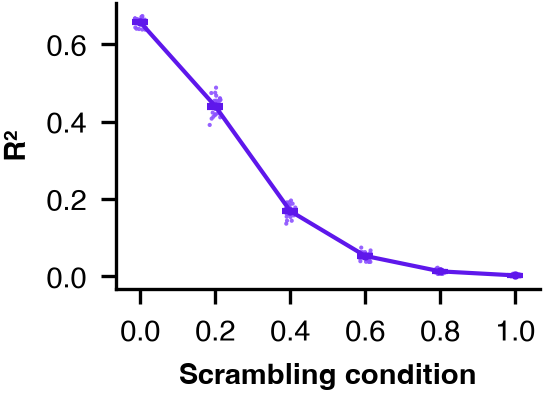

In [131]:
import numpy as np
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

fig, ax = plt.subplots(figsize=(2, 1.5))

# jittered individual points
jitter_strength = 0.015
for cond in df["condition"].unique():
    sub = df[df["condition"] == cond]
    jittered_x = cond + np.random.uniform(-jitter_strength, jitter_strength, size=len(sub))
    ax.scatter(jittered_x, sub["r_squared"], color="#8c52ff", alpha=0.9, s=1, edgecolor= 'none')

# mean ± SEM line on top
ax.errorbar(summary["condition"], summary["mean"], yerr=summary["sem"],
            marker='o', color="#5e17eb", capsize=2, linewidth=1, zorder=10)

ax.set_xlabel("Scrambling condition")
ax.set_ylabel("R²")
ax.set_xticks(summary["condition"])
sns.despine()
plt.tight_layout()
plt.show()

In [148]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# only the adjacent comparisons you want
comparisons = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]

# reshape to paired format: one row per cell_id, one column per condition
paired = df.pivot_table(index="cell_id", columns="condition", values="r_squared").dropna()

raw_results = []
raw_pvals = []

for c1, c2 in comparisons:
    x = paired[c1]
    y = paired[c2]
    stat, p = wilcoxon(x, y, alternative="two-sided", zero_method="wilcox", method="auto")
    raw_results.append((c1, c2, stat, p))
    raw_pvals.append(p)

# multiple-comparison correction across only these 5 comparisons
reject, pvals_adj, _, _ = multipletests(raw_pvals, alpha=0.05, method="holm")

print("Paired Wilcoxon tests with Holm correction:")
for (c1, c2, stat, p), rej, p_adj in zip(raw_results, reject, pvals_adj):
    print(f"{c1} vs {c2}: W={stat:.3f}, raw p={p:.4g}, Holm p={p_adj:.4g}, significant={rej}")

Paired Wilcoxon tests with Holm correction:
0.0 vs 0.2: W=0.000, raw p=1.863e-09, Holm p=9.313e-09, significant=True
0.2 vs 0.4: W=0.000, raw p=1.863e-09, Holm p=9.313e-09, significant=True
0.4 vs 0.6: W=0.000, raw p=1.863e-09, Holm p=9.313e-09, significant=True
0.6 vs 0.8: W=0.000, raw p=1.863e-09, Holm p=9.313e-09, significant=True
0.8 vs 1.0: W=0.000, raw p=1.863e-09, Holm p=9.313e-09, significant=True


In [160]:
diff = paired[0.0] - paired[0.2]
print((diff > 0).sum(), (diff < 0).sum(), (diff == 0).sum())
print(diff.describe())

30 0 0
count    30.000000
mean      0.216965
std       0.025104
min       0.149787
25%       0.200692
50%       0.221387
75%       0.229877
max       0.267643
dtype: float64


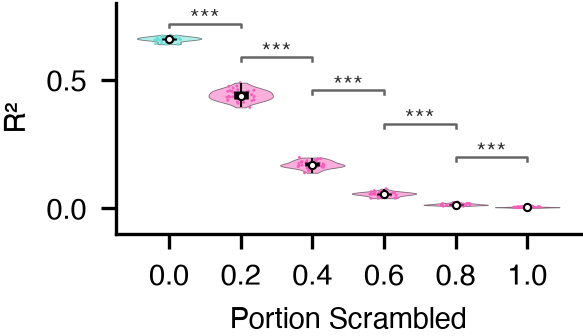

In [203]:
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')
conditions = sorted(df["condition"].unique())
data = [df.loc[df["condition"] == c, "r_squared"].values for c in conditions]

fig, ax = plt.subplots(figsize=(2.0, 1.0))

parts = ax.violinplot(data, positions=conditions, widths=0.18,
                       showmeans=False, showmedians=False, showextrema=False)

def adjacent_values(sorted_vals, q1, q3):
    iqr = q3 - q1
    upper_adjacent = q3 + 1.5 * iqr
    upper_adjacent = np.clip(upper_adjacent, q3, sorted_vals[-1])

    lower_adjacent = q1 - 1.5 * iqr
    lower_adjacent = np.clip(lower_adjacent, sorted_vals[0], q1)
    return lower_adjacent, upper_adjacent

quartile1, medians, quartile3, whiskers_min, whiskers_max = [], [], [], [], []
for group_data in data:  # your `data` list from the violin plot, one array per condition
    sorted_vals = np.sort(group_data)
    q1, med, q3 = np.percentile(sorted_vals, [25, 50, 75])
    w_min, w_max = adjacent_values(sorted_vals, q1, q3)
    quartile1.append(q1); medians.append(med); quartile3.append(q3)
    whiskers_min.append(w_min); whiskers_max.append(w_max)

# use actual numeric condition values as x-positions instead of 1,2,3...
positions = np.array(conditions)

# style the violins
colors = ["#66dfd8", "#f55ebb", "#f55ebb", "#f55ebb", "#f55ebb", "#f55ebb"]
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_edgecolor('black')
    pc.set_alpha(0.5)
    pc.set_linewidth(0.2)

# style the mean/extrema lines (returned as separate LineCollection objects)
for key in ['cmeans', 'cmaxes', 'cmins', 'cbars']:
    if key in parts:
        parts[key].set_color('#5e17eb')
        parts[key].set_linewidth(1)

# jittered individual points
jitter_colors = ["#66dfd8", "#f55ebb", "#f55ebb", "#f55ebb", "#f55ebb", "#f55ebb"]
jitter_strength = 0.04
for cond, color in zip(df["condition"].unique(), jitter_colors):
    sub = df[df["condition"] == cond]
    jittered_x = cond + np.random.uniform(-jitter_strength, jitter_strength, size=len(sub))
    ax.scatter(jittered_x, sub["r_squared"], color=color, alpha=1, s=0.5, edgecolor= 'none')

ax.scatter(positions, medians, marker='o', color='white', s=3, zorder=3, edgecolors='black', linewidth=0.5)
ax.vlines(positions, quartile1, quartile3, color='black', linestyle='-', lw=3.5, alpha=1.0, zorder=2)
ax.vlines(positions, whiskers_min, whiskers_max, color='black', linestyle='-', lw=0.5, zorder=2)

## SIGNIFICANCE STUFF
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# build annotations from the corrected p-values
sig_annotations = []
for (c1, c2), p_adj in zip(comparisons, pvals_adj):
    sig_annotations.append((c1, c2, p_adj, p_to_stars(p_adj)))

# bracket geometry
y_max_data = max(whiskers_max)
bracket_base = y_max_data + 0.03
bracket_step = 0.13
bracket_height = 0.015

for i, (c1, c2, p_adj, stars) in enumerate(sig_annotations):
    y = bracket_base - i * bracket_step
    ax.plot(
        [c1, c1, c2, c2],
        [y, y + bracket_height, y + bracket_height, y],
        color="black",
        linewidth=0.6,
        clip_on=False,
        alpha=0.6,
    )
    ax.text(
        (c1 + c2) / 2,
        y - bracket_height,
        stars,
        ha="center",
        va="bottom",
        fontsize=6,
        clip_on=False,
        alpha=0.8,
    )

ax.set_ylim(-0.1, bracket_base + len(sig_annotations) * bracket_step + 0.05)

#for _, row in summary.iterrows():
    #ax.annotate(f"{row['mean']:.2f}", (row["condition"], row["mean"]),
    #ax.annotate(rf"$\bar{{x}}$={row['mean']:.2f}", (row["condition"], row["mean"]),
                #textcoords="offset points", xytext=(0, 5), fontsize=5, ha='center', fontstyle='normal')
ax.set_ylim(-0.1, 0.8)
ax.set_xlabel("Portion Scrambled", fontweight= 'normal')
ax.set_ylabel("R²", fontweight= 'normal')
ax.set_xticks(conditions)
#plt.tight_layout()
plt.savefig('/Users/liviastein/STDP_Theta-1/Final_Figures/PrecessionR2_short.pdf', transparent=True)
plt.show()

### test whether normally distributed

In [105]:
# shapiro-wilk test for normality
from scipy.stats import shapiro

normality_tests = {}
for condition in df["condition"].unique():
    sub_df = df[df["condition"] == condition]
    stat, p_value = shapiro(sub_df["r_squared"])
    normality_tests[condition] = (stat, p_value)

print("Shapiro-Wilk test results (statistic, p-value) for each condition:")
for condition, (stat, p_value) in normality_tests.items():
    print(f"Condition {condition}: Statistic={stat:.4f}, p-value={p_value:.4f}")
    

Shapiro-Wilk test results (statistic, p-value) for each condition:
Condition 0.0: Statistic=0.9281, p-value=0.0436
Condition 0.2: Statistic=0.9908, p-value=0.9945
Condition 0.4: Statistic=0.9777, p-value=0.7610
Condition 0.6: Statistic=0.9559, p-value=0.2425
Condition 0.8: Statistic=0.9655, p-value=0.4256
Condition 1.0: Statistic=0.9610, p-value=0.3289


### Difference in means -> any difference?
We use Kruskal - wallis bcs condition 0.0 is borderline not normal.

p-value shows at least one value differs from the rest

In [76]:
# test for difference in means across conditions using Kruskal-Wallis H-test
from scipy.stats import kruskal

kw_results = {}
for condition in df["condition"].unique():
    sub_df = df[df["condition"] == condition]
    kw_results[condition] = sub_df["r_squared"].values

stat, p_value = kruskal(*kw_results.values())
print(f"Kruskal-Wallis H-test results: Statistic={stat:.4f}, p-value={p_value:.4f}")

Kruskal-Wallis H-test results: Statistic=173.9890, p-value=0.0000


In [204]:
# friedman test
from scipy.stats import friedmanchisquare
# prepare data for friedman test
friedman_data = [df[df["condition"] == condition]["r_squared"].values for condition in df["condition"].unique()]
stat, p_value = friedmanchisquare(*friedman_data)
print(f"Friedman test results: Statistic={stat:.4f}, p-value={p_value:.4f}")


Friedman test results: Statistic=150.0000, p-value=0.0000


In [144]:
# pairwise comparison with dunn's test and Bonferroni correction
from scikit_posthocs import posthoc_dunn

dunn_results = posthoc_dunn(df, val_col='r_squared', group_col='condition', p_adjust='bonferroni')
print("Pairwise comparisons with Dunn's test and Bonferroni correction:")
print(dunn_results)

# print comparisons that are significant after Bonferroni correction
#def p_to_stars(p):
#    if p < 0.0001: return "****"
#    elif p < 0.001: return "***"
#    elif p < 0.01: return "**"
#    elif p < 0.05: return "*"
#    else: return "ns"



Pairwise comparisons with Dunn's test and Bonferroni correction:
              0.0           0.2           0.4           0.6           0.8  \
0.0  1.000000e+00  3.863287e-01  1.230744e-04  3.355636e-10  6.716662e-18   
0.2  3.863287e-01  1.000000e+00  3.863287e-01  1.230744e-04  3.243877e-10   
0.4  1.230744e-04  3.863287e-01  1.000000e+00  3.863287e-01  1.202602e-04   
0.6  3.355636e-10  1.230744e-04  3.863287e-01  1.000000e+00  3.814201e-01   
0.8  6.716662e-18  3.243877e-10  1.202602e-04  3.814201e-01  1.000000e+00   
1.0  1.143117e-27  7.345398e-18  3.471162e-10  1.259515e-04  3.963102e-01   

              1.0  
0.0  1.143117e-27  
0.2  7.345398e-18  
0.4  3.471162e-10  
0.6  1.259515e-04  
0.8  3.963102e-01  
1.0  1.000000e+00  


## Skew Plots

In [166]:
# import data frame
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# import r2_by_condition.csv file
df_skew = pd.read_csv('/Users/liviastein/STDP_Theta-1/ResultPipelines/skew_by_condition.csv')
df_skew.head()

,condition,skew
0,0.0,-0.482065
1,1.0,-0.258888
2,NaN,-0.016717
3,0.8,-0.356461
4,0.6,-0.378124


slope=0.208, R²=0.940, p=0.0014


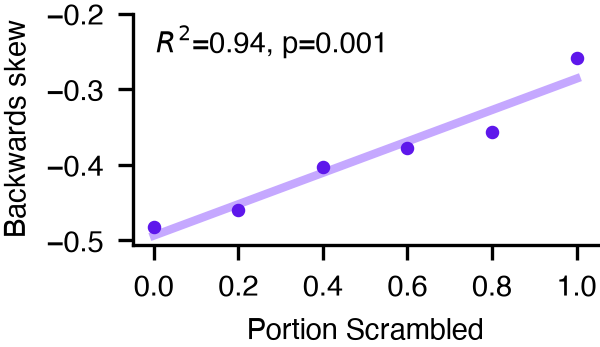

In [201]:
import matplotlib.pyplot as plt
from scipy import stats
df_skew_clean = df_skew.dropna(subset=["skew", "condition"])
skew_values = df_skew_clean["skew"]
conditions = df_skew_clean["condition"]

slope, intercept, r_value, p_value, std_err = stats.linregress(conditions, skew_values)
r_squared = r_value ** 2

print(f"slope={slope:.3f}, R²={r_squared:.3f}, p={p_value:.4f}")

fig, ax = plt.subplots(figsize=(2, 1))
ax.scatter(conditions, skew_values, color='#5e17eb', s=5, zorder=3)

x_line = np.linspace(conditions.min(), conditions.max(), 100)
y_line = slope * x_line + intercept
ax.plot(x_line, y_line, color='#8c52ff', linewidth=2, linestyle='-', alpha=0.5)

ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticks([-0.5, -0.4, -0.3, -0.2])
ax.set_xlabel("Portion Scrambled", fontweight='normal')
ax.set_ylabel("Backwards skew", fontweight='normal')
ax.text(0.05, 0.95, rf"$R^2$={r_squared:.2f}, p={p_value:.3f}",
        transform=ax.transAxes, fontsize=7, va='top')

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
#plt.tight_layout()
plt.savefig('/Users/liviastein/STDP_Theta-1/Final_Figures/PrecessionSkew.pdf', transparent=True)
plt.show()

In [196]:
from scipy.stats import spearmanr
rho, p_spearman = spearmanr(conditions, skew_values)
print(f"Spearman rho={rho:.3f}, p={p_spearman:.4f}")

Spearman rho=1.000, p=0.0000
